In [1]:
# ============================================================
# ACTIVIDAD 5
# Proyecto: ConectaSegura - abandono de clientes
# ============================================================

from pathlib import Path
import hashlib
import json

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# ------------------------------------------------------------
# 1. Crear estructura de carpetas
# ------------------------------------------------------------

proyecto = Path("/content/Actividad5")

carpeta_original = proyecto / "datos" / "datos_ini"
carpeta_limpia = proyecto / "datos" / "datos_limp"
carpeta_fuentes = proyecto / "fuentes"
carpeta_graficas = proyecto / "visualizaciones"

for carpeta in [
    carpeta_original,
    carpeta_limpia,
    carpeta_fuentes,
    carpeta_graficas
]:
    carpeta.mkdir(parents=True, exist_ok=True)

print("Carpetas creadas en:", proyecto)

Carpetas creadas en: /content/Actividad5


In [3]:
# ------------------------------------------------------------
# 2. Descargar y guardar el archivo original
# ------------------------------------------------------------

url = (
    "https://raw.githubusercontent.com/"
    "IBM/telco-customer-churn-on-icp4d/master/"
    "data/Telco-Customer-Churn.csv"
)

ruta_original = carpeta_original / "telco_clientes_original.csv"

# Descargar los bytes para conservar una copia sin modificaciones
import requests

respuesta = requests.get(url, timeout=60)
respuesta.raise_for_status()

ruta_original.write_bytes(respuesta.content)

# Huella del archivo para identificar la versión descargada
sha256 = hashlib.sha256(respuesta.content).hexdigest()

print("Archivo original guardado en:", ruta_original)
print("SHA-256:", sha256)

Archivo original guardado en: /content/Actividad5/datos/datos_ini/telco_clientes_original.csv
SHA-256: 16320c9c1ec72448db59aa0a26a0b95401046bef5d02fd3aeb906448e3055e91


In [4]:
# ------------------------------------------------------------
# 3. Cargar y explorar los datos
# ------------------------------------------------------------

datos = pd.read_csv(ruta_original)

print("\nDimensiones originales:", datos.shape)
print("\nPrimeras filas:")
display(datos.head())

print("\nTipos de datos:")
display(datos.dtypes.to_frame("tipo"))

print("\nValores faltantes antes de la limpieza:")
display(datos.isna().sum().to_frame("nulos"))


Dimensiones originales: (7043, 21)

Primeras filas:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Tipos de datos:


,tipo
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object



Valores faltantes antes de la limpieza:


,nulos
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [5]:
# ------------------------------------------------------------
# 4. Revisión de duplicados
# ------------------------------------------------------------

filas_duplicadas = datos.duplicated().sum()
ids_duplicados = datos["customerID"].duplicated().sum()

print("\nFilas completamente duplicadas:", filas_duplicadas)
print("Identificadores de cliente repetidos:", ids_duplicados)

# Se eliminan únicamente filas completamente idénticas.
# Los IDs repetidos que no sean filas idénticas se dejan para revisión.
datos_limpios = datos.drop_duplicates().copy()

ids_repetidos_restantes = (
    datos_limpios["customerID"].duplicated(keep=False).sum()
)

print(
    "Filas con ID repetido que requieren revisión:",
    ids_repetidos_restantes
)


Filas completamente duplicadas: 0
Identificadores de cliente repetidos: 0
Filas con ID repetido que requieren revisión: 0


In [6]:
# ------------------------------------------------------------
# 5. Limpieza básica
# ------------------------------------------------------------

# Eliminar espacios al inicio y final de textos.
columnas_texto = datos_limpios.select_dtypes(
    include=["object", "string"]
).columns

for columna in columnas_texto:
    datos_limpios[columna] = (
        datos_limpios[columna]
        .astype("string")
        .str.strip()
    )

# Convertir TotalCharges a numérico.
# Los valores vacíos o no convertibles se registran como nulos.
datos_limpios["TotalCharges"] = pd.to_numeric(
    datos_limpios["TotalCharges"],
    errors="coerce"
)

# Verificar categorías de la variable objetivo.
valores_objetivo = set(
    datos_limpios["Churn"].dropna().unique()
)

print("\nCategorías observadas en Churn:", valores_objetivo)

if not valores_objetivo.issubset({"Yes", "No"}):
    print("ATENCIÓN: existen categorías inesperadas en Churn.")

print("\nValores faltantes después de la limpieza básica:")
display(
    datos_limpios.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("nulos")
)

print("\nDimensiones después de limpieza:", datos_limpios.shape)


Categorías observadas en Churn: {'Yes', 'No'}

Valores faltantes después de la limpieza básica:


,nulos
TotalCharges,11
gender,0
SeniorCitizen,0
Partner,0
customerID,0
Dependents,0
tenure,0
MultipleLines,0
PhoneService,0
OnlineSecurity,0



Dimensiones después de limpieza: (7043, 21)


In [7]:
# ------------------------------------------------------------
# 6. Guardar archivo limpio y metadatos
# ------------------------------------------------------------

ruta_limpia = carpeta_limpia / "telco_clientes_limpio.csv"

datos_limpios.to_csv(ruta_limpia, index=False)

metadatos = {
    "fuente": url,
    "sha256_archivo_original": sha256,
    "filas_originales": int(datos.shape[0]),
    "columnas_originales": int(datos.shape[1]),
    "filas_duplicadas_identicas": int(filas_duplicadas),
    "ids_duplicados_originales": int(ids_duplicados),
    "filas_limpias": int(datos_limpios.shape[0]),
    "nulos_totalcharges": int(datos_limpios["TotalCharges"].isna().sum())
}

ruta_metadatos = carpeta_limpia / "metadatos_limpieza.json"

ruta_metadatos.write_text(
    json.dumps(metadatos, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nArchivo limpio:", ruta_limpia)
print("Metadatos:", ruta_metadatos)


Archivo limpio: /content/Actividad5/datos/datos_limp/telco_clientes_limpio.csv
Metadatos: /content/Actividad5/datos/datos_limp/metadatos_limpieza.json


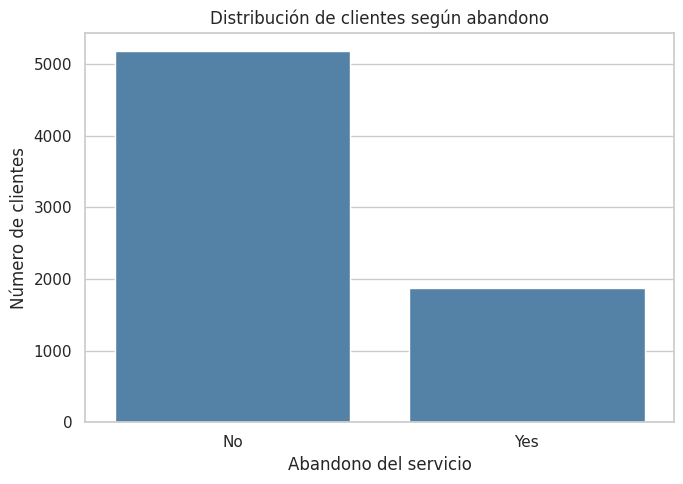

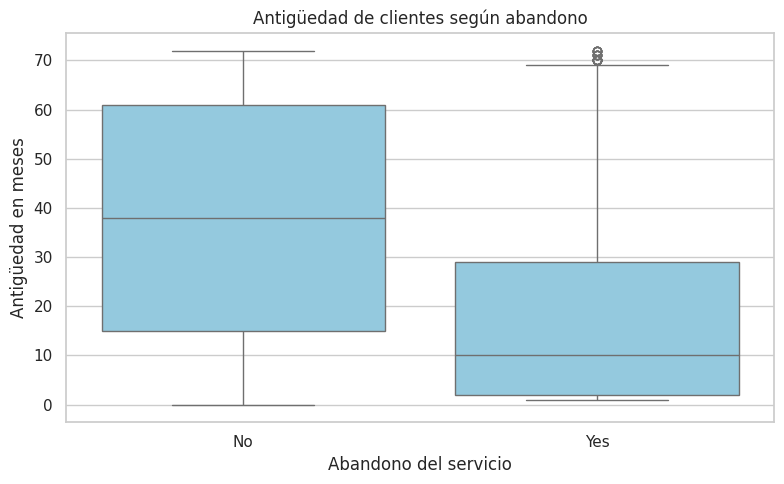

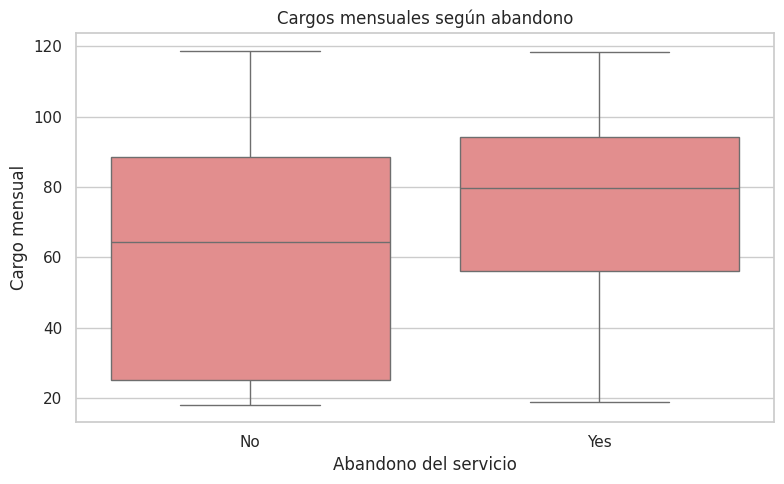


Resumen por categoría de abandono:


,clientes,antiguedad_mediana,cargo_mensual_mediano
Churn,,,
No,5174,38.0,64.425
Yes,1869,10.0,79.650



Punto 1 ejecutado: revisa las tablas y las gráficas.


In [8]:
# ------------------------------------------------------------
# 7. Visualizaciones
# ------------------------------------------------------------

sns.set_theme(style="whitegrid")

# Gráfica 1: distribución de la variable objetivo
plt.figure(figsize=(7, 5))
sns.countplot(
    data=datos_limpios,
    x="Churn",
    order=["No", "Yes"],
    color="steelblue"
)
plt.title("Distribución de clientes según abandono")
plt.xlabel("Abandono del servicio")
plt.ylabel("Número de clientes")
plt.tight_layout()
plt.savefig(
    carpeta_graficas / "01_distribucion_abandono.png",
    dpi=150
)
plt.show()

# Gráfica 2: antigüedad y abandono
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=datos_limpios,
    x="Churn",
    y="tenure",
    order=["No", "Yes"],
    color="skyblue"
)
plt.title("Antigüedad de clientes según abandono")
plt.xlabel("Abandono del servicio")
plt.ylabel("Antigüedad en meses")
plt.tight_layout()
plt.savefig(
    carpeta_graficas / "02_antiguedad_abandono.png",
    dpi=150
)
plt.show()

# Gráfica 3: cargos mensuales y abandono
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=datos_limpios,
    x="Churn",
    y="MonthlyCharges",
    order=["No", "Yes"],
    color="lightcoral"
)
plt.title("Cargos mensuales según abandono")
plt.xlabel("Abandono del servicio")
plt.ylabel("Cargo mensual")
plt.tight_layout()
plt.savefig(
    carpeta_graficas / "03_cargos_abandono.png",
    dpi=150
)
plt.show()

# Tabla para apoyar la interpretación.
resumen = (
    datos_limpios.groupby("Churn")
    .agg(
        clientes=("customerID", "count"),
        antiguedad_mediana=("tenure", "median"),
        cargo_mensual_mediano=("MonthlyCharges", "median")
    )
)

print("\nResumen por categoría de abandono:")
display(resumen)

print("\nPunto 1 ejecutado: revisa las tablas y las gráficas.")

In [9]:
# ============================================================
# ACTIVIDAD 5 - PUNTO 2
# Entrenamiento y comparación de modelos
# ============================================================

from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("Herramientas importadas correctamente.")

Herramientas importadas correctamente.


In [10]:
# Ruta del archivo generado en el Punto 1
ruta_datos = Path(
    "/content/Actividad5/datos/datos_limp/"
    "telco_clientes_limpio.csv"
)

if not ruta_datos.exists():
    raise FileNotFoundError(
        "No se encontró el archivo limpio. "
        "Vuelve a ejecutar el Punto 1 o restaura el ZIP en /content/."
    )

datos_modelo = pd.read_csv(ruta_datos)

print("Dimensiones:", datos_modelo.shape)
print("\nValores faltantes:")
display(datos_modelo.isna().sum().sort_values(ascending=False).head())

print("\nDistribución de la variable objetivo:")
display(datos_modelo["Churn"].value_counts())

Dimensiones: (7043, 21)

Valores faltantes:


,0
TotalCharges,11
gender,0
SeniorCitizen,0
Partner,0
customerID,0



Distribución de la variable objetivo:


,count
Churn,
No,5174
Yes,1869


In [11]:
# Revisar que la variable objetivo tenga las categorías esperadas
categorias = set(datos_modelo["Churn"].dropna().unique())

if categorias != {"No", "Yes"} or datos_modelo["Churn"].isna().any():
    raise ValueError(
        f"Revisa la variable Churn. Categorías encontradas: {categorias}"
    )

# 0 = permanece; 1 = abandona
y = datos_modelo["Churn"].map({"No": 0, "Yes": 1})

# customerID se excluye porque es un identificador.
# Churn se excluye porque es el resultado que deseamos predecir.
X = datos_modelo.drop(columns=["customerID", "Churn"])

# División: 80 % entrenamiento y 20 % prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))

print("\nProporción de clases en entrenamiento:")
display(y_train.value_counts(normalize=True).rename("proporción"))

print("\nProporción de clases en prueba:")
display(y_test.value_counts(normalize=True).rename("proporción"))

Registros de entrenamiento: 5634
Registros de prueba: 1409

Proporción de clases en entrenamiento:


,proporción
Churn,
0,0.734647
1,0.265353



Proporción de clases en prueba:


,proporción
Churn,
0,0.734564
1,0.265436


In [12]:
# Identificar columnas según su tipo
columnas_numericas = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

columnas_categoricas = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Variables numéricas:")
print(columnas_numericas)

print("\nVariables categóricas:")
print(columnas_categoricas)

# Preparación de variables numéricas
preparacion_numerica = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler())
])

# Preparación de variables categóricas
preparacion_categorica = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("codificacion", OneHotEncoder(handle_unknown="ignore"))
])

# Unir los tratamientos
preprocesador = ColumnTransformer(
    transformers=[
        ("numericas", preparacion_numerica, columnas_numericas),
        ("categoricas", preparacion_categorica, columnas_categoricas)
    ]
)

print("\nPipeline de preparación configurado.")

Variables numéricas:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Variables categóricas:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Pipeline de preparación configurado.


In [13]:
# Validación cruzada estratificada de 3 particiones
validacion = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# ------------------------------------------------------------
# Modelo 1: regresión logística
# ------------------------------------------------------------

pipeline_logistica = Pipeline(steps=[
    ("preparacion", preprocesador),
    ("modelo", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

parametros_logistica = {
    "modelo__C": [0.1, 1.0, 10.0],
    "modelo__class_weight": [None, "balanced"]
}

# ------------------------------------------------------------
# Modelo 2: bosque aleatorio
# ------------------------------------------------------------

pipeline_bosque = Pipeline(steps=[
    ("preparacion", preprocesador),
    ("modelo", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

parametros_bosque = {
    "modelo__n_estimators": [100, 200],
    "modelo__max_depth": [None, 10],
    "modelo__min_samples_leaf": [1, 3],
    "modelo__class_weight": [None, "balanced"]
}

# Búsqueda de hiperparámetros.
# Se optimiza F1 para la clase positiva: abandono.
busquedas = {
    "Regresión logística": GridSearchCV(
        estimator=pipeline_logistica,
        param_grid=parametros_logistica,
        scoring="f1",
        cv=validacion,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    ),
    "Bosque aleatorio": GridSearchCV(
        estimator=pipeline_bosque,
        param_grid=parametros_bosque,
        scoring="f1",
        cv=validacion,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )
}

for nombre, busqueda in busquedas.items():
    print(f"\nEntrenando: {nombre}...")
    busqueda.fit(X_train, y_train)

    print("Mejor F1 promedio en validación cruzada:",
          round(busqueda.best_score_, 4))

    print("Mejores hiperparámetros:")
    print(busqueda.best_params_)

print("\nEntrenamiento y ajuste terminados.")


Entrenando: Regresión logística...
Mejor F1 promedio en validación cruzada: 0.6291
Mejores hiperparámetros:
{'modelo__C': 1.0, 'modelo__class_weight': 'balanced'}

Entrenando: Bosque aleatorio...
Mejor F1 promedio en validación cruzada: 0.6349
Mejores hiperparámetros:
{'modelo__class_weight': 'balanced', 'modelo__max_depth': 10, 'modelo__min_samples_leaf': 3, 'modelo__n_estimators': 200}

Entrenamiento y ajuste terminados.


In [14]:
resultados = []
predicciones = {}

for nombre, busqueda in busquedas.items():

    modelo_final = busqueda.best_estimator_

    # Predicción de clase con el umbral predeterminado
    y_pred = modelo_final.predict(X_test)

    # Probabilidad de la clase positiva: abandono
    y_prob = modelo_final.predict_proba(X_test)[:, 1]

    predicciones[nombre] = {
        "modelo": modelo_final,
        "clases": y_pred,
        "probabilidades": y_prob
    }

    resultados.append({
        "Modelo": nombre,
        "F1_CV": busqueda.best_score_,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, y_prob)
    })

    print(f"\n{'=' * 55}")
    print(nombre)
    print("=" * 55)

    print(classification_report(
        y_test,
        y_pred,
        target_names=["Permanece", "Abandona"],
        zero_division=0
    ))

tabla_resultados = pd.DataFrame(resultados)

print("\nComparación de modelos:")
display(tabla_resultados.round(4))


Regresión logística
              precision    recall  f1-score   support

   Permanece       0.90      0.72      0.80      1035
    Abandona       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409


Bosque aleatorio
              precision    recall  f1-score   support

   Permanece       0.89      0.78      0.83      1035
    Abandona       0.55      0.73      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409


Comparación de modelos:


,Modelo,F1_CV,Accuracy,Precision,Recall,F1,ROC_AUC
0,Regresión logística,0.6291,0.7381,0.5043,0.7834,0.6136,0.8413
1,Bosque aleatorio,0.6349,0.7672,0.5458,0.7326,0.6256,0.8406


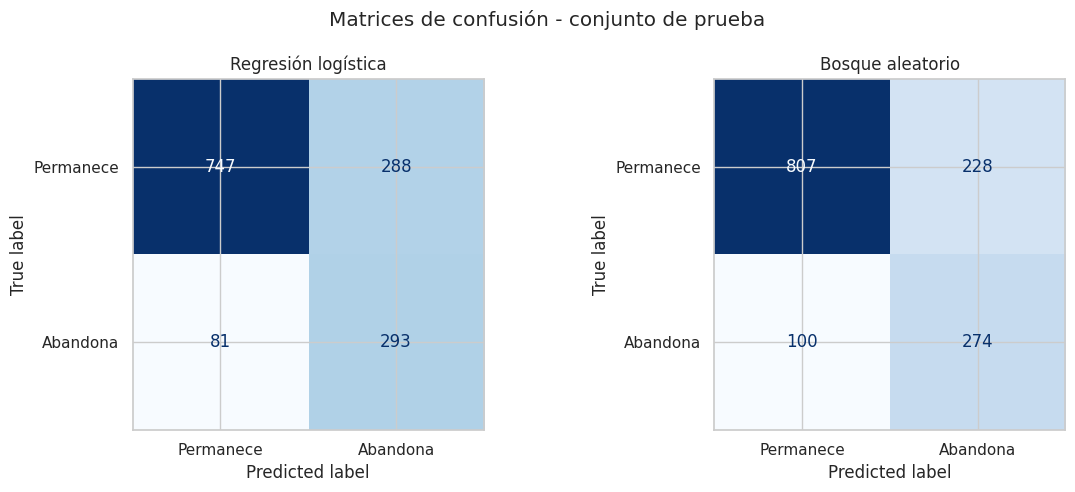

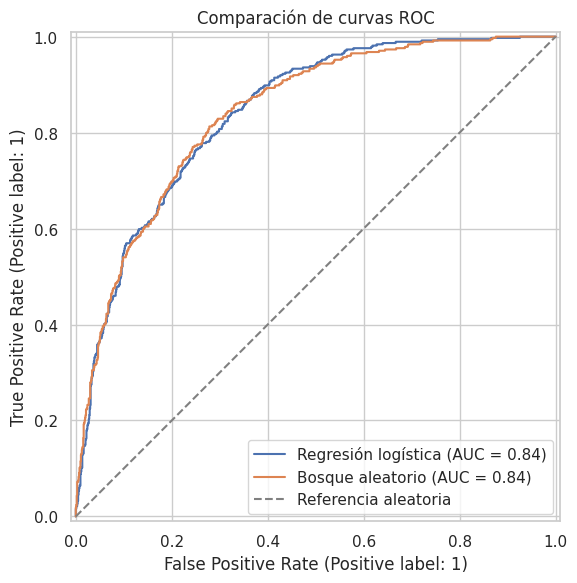

In [15]:
carpeta_resultados = Path("/content/Actividad5/resultados")
carpeta_resultados.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Matrices de confusión
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (nombre, resultado) in zip(axes, predicciones.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        resultado["clases"],
        display_labels=["Permanece", "Abandona"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(nombre)

plt.suptitle("Matrices de confusión - conjunto de prueba")
plt.tight_layout()

plt.savefig(
    carpeta_resultados / "matrices_confusion.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Curvas ROC
# ------------------------------------------------------------

plt.figure(figsize=(7, 6))
ax = plt.gca()

for nombre, resultado in predicciones.items():
    RocCurveDisplay.from_predictions(
        y_test,
        resultado["probabilidades"],
        name=nombre,
        ax=ax
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Referencia aleatoria"
)

ax.set_title("Comparación de curvas ROC")
ax.legend()
plt.tight_layout()

plt.savefig(
    carpeta_resultados / "curvas_roc.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [16]:
# Guardar tabla de métricas
ruta_metricas = carpeta_resultados / "comparacion_modelos.csv"
tabla_resultados.to_csv(ruta_metricas, index=False)

# Guardar mejores parámetros y F1 de validación cruzada
resumen_busquedas = {}

for nombre, busqueda in busquedas.items():
    resumen_busquedas[nombre] = {
        "mejor_f1_validacion_cruzada": float(busqueda.best_score_),
        "mejores_hiperparametros": busqueda.best_params_
    }

ruta_parametros = carpeta_resultados / "mejores_parametros.json"

ruta_parametros.write_text(
    json.dumps(resumen_busquedas, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("Archivos guardados en:", carpeta_resultados)

for archivo in carpeta_resultados.iterdir():
    print("-", archivo.name)

Archivos guardados en: /content/Actividad5/resultados
- curvas_roc.png
- comparacion_modelos.csv
- matrices_confusion.png
- mejores_parametros.json


In [17]:
#%pip install -q "mlflow==2.22.0"

In [18]:
#%pip install -q "mlflow==2.22.0" "SQLAlchemy>=2.0,<2.1"

In [19]:
from pathlib import Path
import hashlib
import json
import platform
import sys

import mlflow
import mlflow.sklearn
import pandas as pd
import sklearn

from mlflow.tracking import MlflowClient

# Verificar que existan los resultados del Punto 2.
variables_necesarias = [
    "busquedas",
    "tabla_resultados",
    "X_test",
    "y_test"
]

faltantes = [
    nombre for nombre in variables_necesarias
    if nombre not in globals()
]

if faltantes:
    raise RuntimeError(
        "Faltan variables del Punto 2: "
        + ", ".join(faltantes)
        + ". Ejecuta primero las celdas de entrenamiento."
    )

# Carpetas del proyecto
proyecto = Path("/content/Actividad5")
carpeta_mlflow = proyecto / "mlflow"
carpeta_artefactos = carpeta_mlflow / "artefactos"

carpeta_mlflow.mkdir(parents=True, exist_ok=True)
carpeta_artefactos.mkdir(parents=True, exist_ok=True)

# Base SQLite local para los experimentos
ruta_base = carpeta_mlflow / "experimentos.db"
tracking_uri = f"sqlite:///{ruta_base}"

mlflow.set_tracking_uri(tracking_uri)

nombre_experimento = "ConectaSegura_Abandono_Clientes"

# Crear el experimento una sola vez.
# Su ubicación de artefactos quedará registrada en la base.
experimento = mlflow.get_experiment_by_name(nombre_experimento)

if experimento is None:
    experimento_id = mlflow.create_experiment(
        name=nombre_experimento,
        artifact_location=carpeta_artefactos.resolve().as_uri()
    )
else:
    experimento_id = experimento.experiment_id

mlflow.set_experiment(nombre_experimento)

print("Versión de MLflow:", mlflow.__version__)
print("Experimento:", nombre_experimento)
print("ID del experimento:", experimento_id)
print("Base de datos:", ruta_base)
print("Artefactos:", carpeta_artefactos)

2026/10/19 01:58:27 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/19 01:58:27 INFO mlflow.store.db.utils: Updating database tables
INFO  [alembic.runtime.migration] Context impl SQLiteImpl.
INFO  [alembic.runtime.migration] Will assume non-transactional DDL.
INFO  [alembic.runtime.migration] Running upgrade  -> 451aebb31d03, add metric step
INFO  [alembic.runtime.migration] Running upgrade 451aebb31d03 -> 90e64c465722, migrate user column to tags
INFO  [alembic.runtime.migration] Running upgrade 90e64c465722 -> 181f10493468, allow nulls for metric values
INFO  [alembic.runtime.migration] Running upgrade 181f10493468 -> df50e92ffc5e, Add Experiment Tags Table
INFO  [alembic.runtime.migration] Running upgrade df50e92ffc5e -> 7ac759974ad8, Update run tags with larger limit
INFO  [alembic.runtime.migration] Running upgrade 7ac759974ad8 -> 89d4b8295536, create latest metrics table
INFO  [89d4b8295536_create_latest_metrics_table_py] Migration complete!
INFO  

Versión de MLflow: 2.22.0
Experimento: ConectaSegura_Abandono_Clientes
ID del experimento: 1
Base de datos: /content/Actividad5/mlflow/experimentos.db
Artefactos: /content/Actividad5/mlflow/artefactos


In [20]:
ruta_datos = (
    proyecto / "datos" / "datos_limp"
    / "telco_clientes_limpio.csv"
)

if not ruta_datos.exists():
    raise FileNotFoundError(
        f"No se encontró el archivo de datos: {ruta_datos}"
    )

# Huella de la versión de datos utilizada.
sha256_datos = hashlib.sha256(
    ruta_datos.read_bytes()
).hexdigest()

carpeta_resultados = proyecto / "resultados"
carpeta_temporal = proyecto / "mlflow" / "archivos_registro"
carpeta_temporal.mkdir(parents=True, exist_ok=True)

# Información general para reproducibilidad.
configuracion = {
    "problema": "Clasificación de abandono de clientes",
    "dataset_limpio": str(ruta_datos),
    "sha256_dataset_limpio": sha256_datos,
    "variable_objetivo": "Churn",
    "clase_positiva": "Yes - abandona",
    "proporcion_prueba": 0.20,
    "random_state": 42,
    "validacion_cruzada": "StratifiedKFold, 3 particiones",
    "metrica_ajuste": "F1 de la clase abandono",
    "python": platform.python_version(),
    "scikit_learn": sklearn.__version__,
    "pandas": pd.__version__,
    "mlflow": mlflow.__version__
}

ruta_configuracion = carpeta_temporal / "configuracion_experimento.json"

ruta_configuracion.write_text(
    json.dumps(configuracion, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

ids_ejecuciones = {}

for nombre, busqueda in busquedas.items():

    fila = tabla_resultados.loc[
        tabla_resultados["Modelo"] == nombre
    ].iloc[0]

    nombre_archivo = (
        "regresion_logistica"
        if nombre == "Regresión logística"
        else "bosque_aleatorio"
    )

    # Resultados completos de la búsqueda de hiperparámetros.
    ruta_cv = carpeta_temporal / f"gridsearch_{nombre_archivo}.csv"

    pd.DataFrame(busqueda.cv_results_).to_csv(
        ruta_cv,
        index=False
    )

    with mlflow.start_run(run_name=nombre) as ejecucion:

        # Etiquetas para identificar el experimento.
        mlflow.set_tags({
            "proyecto": "ConectaSegura",
            "caso": "Abandono de clientes",
            "tipo_registro": "modelo entrenado previamente en Colab",
            "sha256_datos": sha256_datos
        })

        # Configuración común.
        mlflow.log_params({
            "modelo": nombre,
            "test_size": 0.20,
            "random_state": 42,
            "cv_folds": 3,
            "scoring_gridsearch": "f1",
            "clase_positiva": "abandona"
        })

        # Mejores hiperparámetros identificados por Grid Search.
        for parametro, valor in busqueda.best_params_.items():
            mlflow.log_param(parametro, str(valor))

        # Métricas de validación cruzada y prueba.
        mlflow.log_metrics({
            "f1_validacion_cruzada": float(fila["F1_CV"]),
            "accuracy_prueba": float(fila["Accuracy"]),
            "precision_prueba": float(fila["Precision"]),
            "recall_prueba": float(fila["Recall"]),
            "f1_prueba": float(fila["F1"]),
            "roc_auc_prueba": float(fila["ROC_AUC"])
        })

        # Guardar el pipeline completo: preparación + modelo.
        # No se usa input_example para evitar registrar datos de clientes.
        modelo_info = mlflow.sklearn.log_model(
            sk_model=busqueda.best_estimator_,
            artifact_path="modelo"
        )

        # Archivos de configuración y búsqueda.
        mlflow.log_artifact(
            str(ruta_configuracion),
            artifact_path="documentacion"
        )

        mlflow.log_artifact(
            str(ruta_cv),
            artifact_path="validacion_cruzada"
        )

        # Resultados y gráficas ya generados en el Punto 2.
        for archivo in [
            "comparacion_modelos.csv",
            "mejores_parametros.json",
            "matrices_confusion.png",
            "curvas_roc.png"
        ]:
            ruta_archivo = carpeta_resultados / archivo

            if ruta_archivo.exists():
                mlflow.log_artifact(
                    str(ruta_archivo),
                    artifact_path="resultados"
                )
            else:
                print("No se encontró:", ruta_archivo)

        ids_ejecuciones[nombre] = {
            "run_id": ejecucion.info.run_id,
            "model_uri": modelo_info.model_uri
        }

        print(f"\nModelo registrado: {nombre}")
        print("Run ID:", ejecucion.info.run_id)
        print("URI del modelo:", modelo_info.model_uri)

# Guardar identificadores para poder consultarlos después.
ruta_ids = carpeta_mlflow / "ids_ejecuciones.json"

ruta_ids.write_text(
    json.dumps(ids_ejecuciones, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nRegistro terminado.")
print("Identificadores guardados en:", ruta_ids)

2026/10/19 01:59:31 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.



Modelo registrado: Regresión logística
Run ID: 74bbed2d649e4d4abbffe05cdf3fa837
URI del modelo: runs:/74bbed2d649e4d4abbffe05cdf3fa837/modelo


2026/10/19 01:59:38 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.



Modelo registrado: Bosque aleatorio
Run ID: b73a2b79e61149fca64ef7b706c5c5ad
URI del modelo: runs:/b73a2b79e61149fca64ef7b706c5c5ad/modelo

Registro terminado.
Identificadores guardados en: /content/Actividad5/mlflow/ids_ejecuciones.json


In [21]:
# Consultar ejecuciones registradas
ejecuciones = mlflow.search_runs(
    experiment_ids=[experimento_id]
)

columnas_mostrar = [
    "run_id",
    "tags.mlflow.runName",
    "metrics.f1_validacion_cruzada",
    "metrics.accuracy_prueba",
    "metrics.precision_prueba",
    "metrics.recall_prueba",
    "metrics.f1_prueba",
    "metrics.roc_auc_prueba"
]

print("Ejecuciones registradas:")
display(
    ejecuciones[
        [col for col in columnas_mostrar if col in ejecuciones.columns]
    ]
)

# Comprobar que se puede recuperar el bosque aleatorio.
uri_bosque = ids_ejecuciones["Bosque aleatorio"]["model_uri"]

modelo_cargado = mlflow.sklearn.load_model(uri_bosque)

prediccion_recuperada = modelo_cargado.predict(X_test.head(5))

print("\nModelo recuperado correctamente desde MLflow.")
print("Predicciones de prueba:", prediccion_recuperada)
print("Referencia: 0 = permanece; 1 = abandona")

Ejecuciones registradas:


,run_id,tags.mlflow.runName,metrics.f1_validacion_cruzada,metrics.accuracy_prueba,metrics.precision_prueba,metrics.recall_prueba,metrics.f1_prueba,metrics.roc_auc_prueba
0,b73a2b79e61149fca64ef7b706c5c5ad,Bosque aleatorio,0.634886,0.767211,0.545817,0.732620,0.625571,0.840600
1,74bbed2d649e4d4abbffe05cdf3fa837,Regresión logística,0.629140,0.738112,0.504303,0.783422,0.613613,0.841298



Modelo recuperado correctamente desde MLflow.
Predicciones de prueba: [0 1 0 0 0]
Referencia: 0 = permanece; 1 = abandona


In [22]:
import subprocess
import time
from google.colab import output

# Si ya existe un servidor iniciado por esta celda, detenerlo.
if "proceso_mlflow" in globals() and proceso_mlflow.poll() is None:
    proceso_mlflow.terminate()
    proceso_mlflow.wait(timeout=10)

archivo_log = open(
    "/content/Actividad5/mlflow/servidor_mlflow.log",
    "w"
)

proceso_mlflow = subprocess.Popen(
    [
        sys.executable, "-m", "mlflow", "ui",
        "--backend-store-uri", tracking_uri,
        "--host", "127.0.0.1",
        "--port", "5000"
    ],
    stdout=archivo_log,
    stderr=subprocess.STDOUT
)

time.sleep(8)

if proceso_mlflow.poll() is not None:
    archivo_log.flush()
    raise RuntimeError(
        "El servidor de MLflow no inició. Revisa el archivo "
        "/content/Actividad5/mlflow/servidor_mlflow.log"
    )

print("Abriendo interfaz de MLflow...")
output.serve_kernel_port_as_window(5000)

Abriendo interfaz de MLflow...
Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [23]:
import shutil
from google.colab import files

ruta_zip = shutil.make_archive(
    "/content/Actividad5_ConectaSegura_con_MLflow",
    "zip",
    "/content/Actividad5"
)

files.download(ruta_zip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>